<a href="https://colab.research.google.com/github/karib3/DL-Engineering/blob/main/CNN/Image_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Problem Statement:
Classify 32x32 RGB image into one of 10 object categories.

#Data Collection:

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
import tarfile

archive_path = "/content/cifar-10-python.tar.gz"

with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall("/content/")
    print("Data extracted successfully!")

/tmp/ipykernel_1154/1376660076.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("/content/")


Data extracted successfully!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torchvision
from torchvision import datasets

train_dataset = datasets.CIFAR10(
    root="/content",
    train=True,
    download=False
)

test_dataset = datasets.CIFAR10(
    root="/content",
    train=False,
    download=False
)

#Exploratory Data Analysis (EDA):

In [ ]:
print("Training samples: ", len(train_dataset))
print("Test samples: ", len(test_dataset))

Training samples:  50000
Test samples:  10000


In [ ]:
print("Classes: ", train_dataset.classes)

Classes:  ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
print("Class to index: ", train_dataset.class_to_idx)

Class to index:  {'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}


In [ ]:
image, label = train_dataset[0]

print("Image type:", type(image))
print("Image shape:", image.size)
print("Label:", label)
print("Class:", train_dataset.classes[label])

Image type: <class 'PIL.Image.Image'>
Image shape: (32, 32)
Label: 6
Class: frog


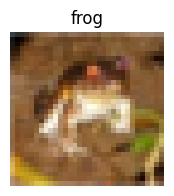

In [ ]:
plt.figure(figsize=(2, 2))
plt.imshow(image)
plt.title(train_dataset.classes[label])
plt.axis("off")
plt.show()

In [ ]:
image_array = np.array(image)

print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Array shape: (32, 32, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [ ]:
print("First 20 pixel values:")
print(image_array.flatten()[:20])

First 20 pixel values:
[ 59  62  63  43  46  45  50  48  43  68  54  42  98  73  52 119  91  63
 139 107]


In [ ]:
print("Pixel mean:", image_array.mean())
print("Pixel standard deviation:", image_array.std())

Pixel mean: 103.447265625
Pixel standard deviation: 51.97371837166704


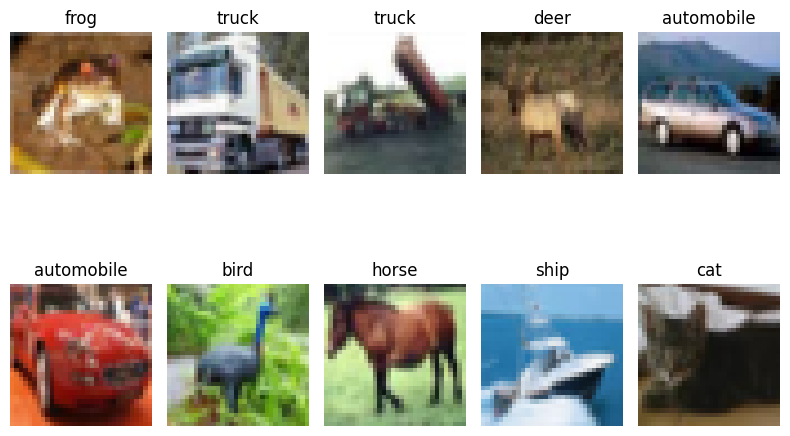

In [ ]:
plt.figure(figsize=(8, 6))

for i in range(10):
    image, label = train_dataset[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(train_dataset.classes[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter

train_labels = train_dataset.targets

class_counts = Counter(train_labels)

for class_index, count in sorted(class_counts.items()):
    print(
        f"{class_index}: "
        f"{train_dataset.classes[class_index]} → "
        f"{count}"
    )

0: airplane → 5000
1: automobile → 5000
2: bird → 5000
3: cat → 5000
4: deer → 5000
5: dog → 5000
6: frog → 5000
7: horse → 5000
8: ship → 5000
9: truck → 5000


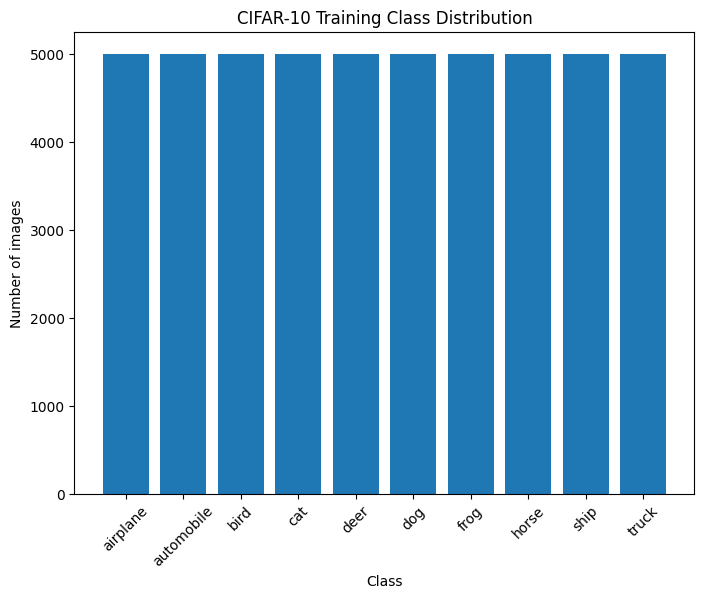

In [ ]:
classes = train_dataset.classes
counts = [class_counts[i] for i in range(len(classes))]

plt.figure(figsize=(8, 6))
plt.bar(classes, counts)
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.title("CIFAR-10 Training Class Distribution")
plt.xticks(rotation=45)
plt.show()

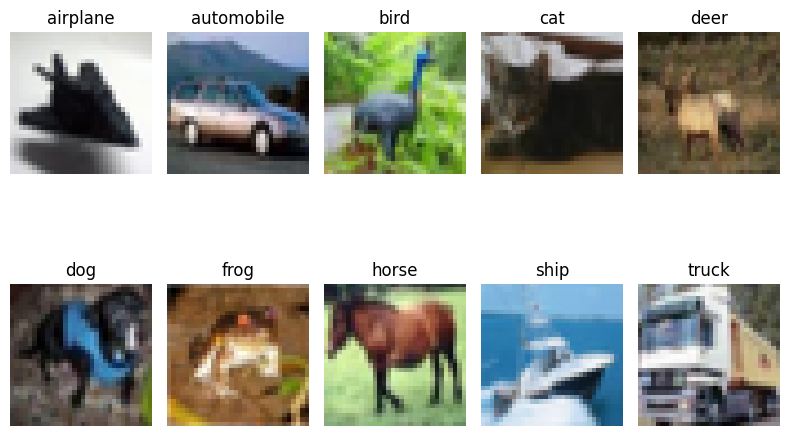

In [ ]:
plt.figure(figsize=(8, 6))

for class_index in range(10):
    for image, label in train_dataset:
        if label == class_index:
            plt.subplot(2, 5, class_index + 1)
            plt.imshow(image)
            plt.title(classes[class_index])
            plt.axis("off")
            break

plt.tight_layout()
plt.show()

#Preprocessing:

In [ ]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

In [ ]:
train_dataset = datasets.CIFAR10(
    root="/content",
    train=True,
    download=False,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="/content",
    train=False,
    download=False,
    transform=transform
)

In [ ]:
image, label = train_dataset[0]

print("Image type:", type(image))
print("Image shape:", image.shape)
print("Label:", label)

Image type: <class 'torch.Tensor'>
Image shape: torch.Size([3, 32, 32])
Label: 6


In [ ]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [ ]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 3, 32, 32])
Batch label shape: torch.Size([64])


In [ ]:
mean = torch.tensor([0.4914, 0.4822, 0.4465])
std = torch.tensor([0.2470, 0.2435, 0.2616])

def denormalize(image):
    image = image.clone()

    for channel in range(3):
        image[channel] = image[channel] * std[channel] + mean[channel]

    return image

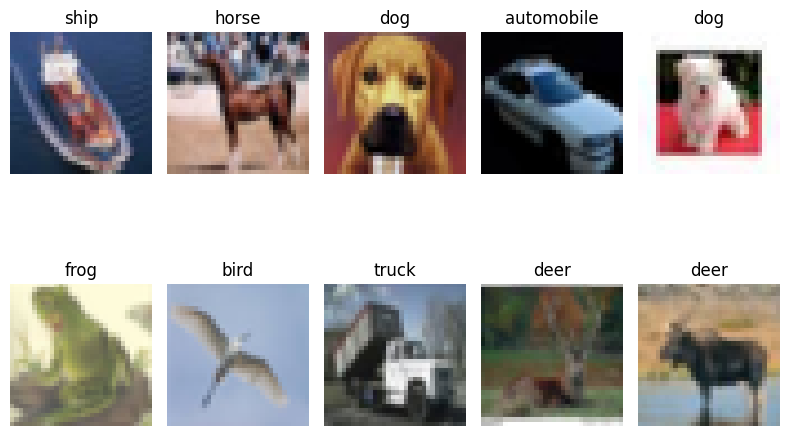

In [ ]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(8, 6))

for i in range(10):
    image = denormalize(images[i])
    image = image.permute(1, 2, 0)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.clamp(0, 1))
    plt.title(train_dataset.classes[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

#Data Augmentation:

In [ ]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

In [ ]:
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

In [ ]:
train_dataset = datasets.CIFAR10(
    root="/content",
    train=True,
    download=False,
    transform=train_transform
)

test_dataset = datasets.CIFAR10(
    root="/content",
    train=False,
    download=False,
    transform=test_transform
)

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

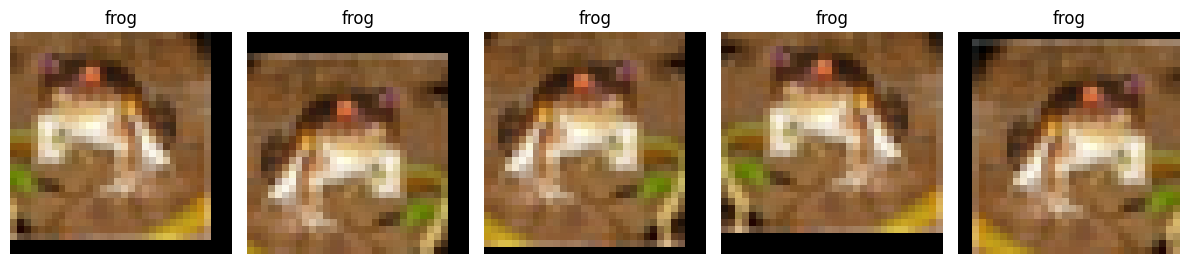

In [ ]:
raw_dataset = datasets.CIFAR10(
    root="/content",
    train=True,
    download=False
)

image, label = raw_dataset[0]

plt.figure(figsize=(12, 3))

for i in range(5):
    augmented_image = train_transform(image)

    augmented_image = denormalize(augmented_image)
    augmented_image = augmented_image.permute(1, 2, 0)

    plt.subplot(1, 5, i + 1)
    plt.imshow(augmented_image.clamp(0, 1))
    plt.title(train_dataset.classes[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)
print(images.min().item())
print(images.max().item())

torch.Size([64, 3, 32, 32])
torch.Size([64])
-1.9894737005233765
2.12648868560791


#Baseline Model (Feedback Neural Network):

In [ ]:
import torch.nn as nn

class BaselineNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3 * 32 * 32, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

model = BaselineNN()

print(model)

BaselineNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Trainable parameters:", total_params)

Trainable parameters: 394634


In [ ]:
images, labels = next(iter(train_loader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])


In [ ]:
print(outputs[0])

tensor([ 0.0133,  0.0595,  0.0148, -0.3598, -0.2067, -0.3169,  0.2012,  0.0819,
         0.0824,  0.0023], grad_fn=<SelectBackward0>)


In [ ]:
predicted_class = outputs[0].argmax()

print("Predicted class index:", predicted_class.item())
print("Predicted class:", train_dataset.classes[predicted_class])
print("Actual class:", train_dataset.classes[labels[0]])

Predicted class index: 6
Predicted class: frog
Actual class: horse


In [ ]:
criterion = nn.CrossEntropyLoss()
loss = criterion(outputs, labels)

print("Initial loss:", loss.item())

Initial loss: 2.300628423690796


In [ ]:
from torch.optim import Adam

optimizer = Adam(model.parameters(), lr=0.001)

num_epochs = 5

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # images = images.to(device)
        # labels = labels.to(device)

        # 1. Forward pass
        outputs = model(images)

        # 2. Calculate loss
        loss = criterion(outputs, labels)

        # 3. Clear previous gradients
        optimizer.zero_grad()

        # 4. Backpropagation
        loss.backward()

        # 5. Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.4f}"
    )

Epoch [1/5] Loss: 1.8397 Accuracy: 0.3434
Epoch [2/5] Loss: 1.6893 Accuracy: 0.3954
Epoch [3/5] Loss: 1.6518 Accuracy: 0.4091
Epoch [4/5] Loss: 1.6226 Accuracy: 0.4229
Epoch [5/5] Loss: 1.6027 Accuracy: 0.4285


#Base Model Evaluation:

In [ ]:
model.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_loss = test_loss / total
test_accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 1.8343
Test Accuracy: 0.4020


#Convolutional Neural Network (CNN):

In [ ]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 2
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x

cnn = CNN()

print(cnn)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in cnn.parameters()
        if p.requires_grad
    )
)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 545098


In [ ]:
images, labels = next(iter(train_loader))

outputs = cnn(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

loss = criterion(outputs, labels)

print("Initial loss:", loss.item())

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])
Initial loss: 2.313394784927368


In [ ]:
cnn_criterion = nn.CrossEntropyLoss()

cnn_optimizer = Adam(
    cnn.parameters(),
    lr=0.001
)

num_epochs = 5

cnn_train_losses = []
cnn_train_accuracies = []

for epoch in range(num_epochs):

    cnn.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Forward pass
        outputs = cnn(images)

        # Loss
        loss = cnn_criterion(outputs, labels)

        # Clear gradients
        cnn_optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        cnn_optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    cnn_train_losses.append(epoch_loss)
    cnn_train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.4f}"
    )

Epoch [1/5] Loss: 1.5303 Accuracy: 0.4415
Epoch [2/5] Loss: 1.2057 Accuracy: 0.5683
Epoch [3/5] Loss: 1.0678 Accuracy: 0.6187
Epoch [4/5] Loss: 0.9899 Accuracy: 0.6475
Epoch [5/5] Loss: 0.9281 Accuracy: 0.6728


In [ ]:
cnn.eval()

cnn_test_loss = 0.0
cnn_correct = 0
cnn_total = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = cnn(images)

        loss = cnn_criterion(outputs, labels)

        cnn_test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        cnn_correct += (predictions == labels).sum().item()
        cnn_total += labels.size(0)

cnn_test_loss = cnn_test_loss / cnn_total
cnn_test_accuracy = cnn_correct / cnn_total

print(f"CNN Test Loss: {cnn_test_loss:.4f}")
print(f"CNN Test Accuracy: {cnn_test_accuracy:.4f}")

CNN Test Loss: 0.8765
CNN Test Accuracy: 0.6933


#CNN Evaluation:

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

all_predictions = []
all_labels = []

cnn.eval()

with torch.no_grad():

    for images, labels in test_loader:

        outputs = cnn(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[742  35  41  30  11   8  14  17  51  51]
 [  5 876   6  15   1   7  15   0  10  65]
 [ 76  11 532  61  40 132 103  24   8  13]
 [ 21   8  56 516  25 241 105  14   7   7]
 [ 23   7 104  59 471  93 167  62  11   3]
 [ 12   4  35 170  20 708  31  15   2   3]
 [  2   3  36  40   7  28 878   2   4   0]
 [ 16   2  27  56  26 154  20 689   1   9]
 [ 85  60  12  28   5  14  11   1 747  37]
 [ 21 129   7  26   1   9  11   8  14 774]]


In [ ]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=classes,
        digits=4
    )
)

              precision    recall  f1-score   support

    airplane     0.7398    0.7420    0.7409      1000
  automobile     0.7718    0.8760    0.8206      1000
        bird     0.6215    0.5320    0.5733      1000
         cat     0.5155    0.5160    0.5157      1000
        deer     0.7759    0.4710    0.5862      1000
         dog     0.5079    0.7080    0.5915      1000
        frog     0.6480    0.8780    0.7456      1000
       horse     0.8281    0.6890    0.7522      1000
        ship     0.8737    0.7470    0.8054      1000
       truck     0.8046    0.7740    0.7890      1000

    accuracy                         0.6933     10000
   macro avg     0.7087    0.6933    0.6920     10000
weighted avg     0.7087    0.6933    0.6920     10000



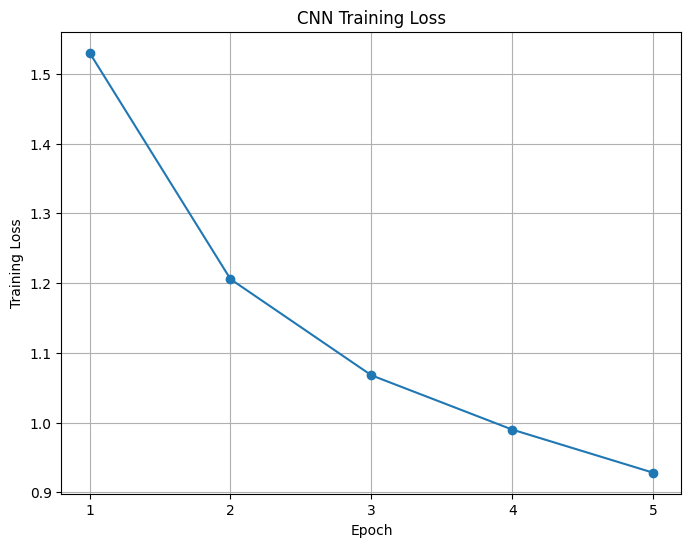

In [ ]:
epochs = range(1, len(cnn_train_losses) + 1)

plt.figure(figsize=(8, 6))

plt.plot(epochs, cnn_train_losses, marker='o')

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CNN Training Loss")

plt.xticks(list(epochs))
plt.grid(True)

plt.show()

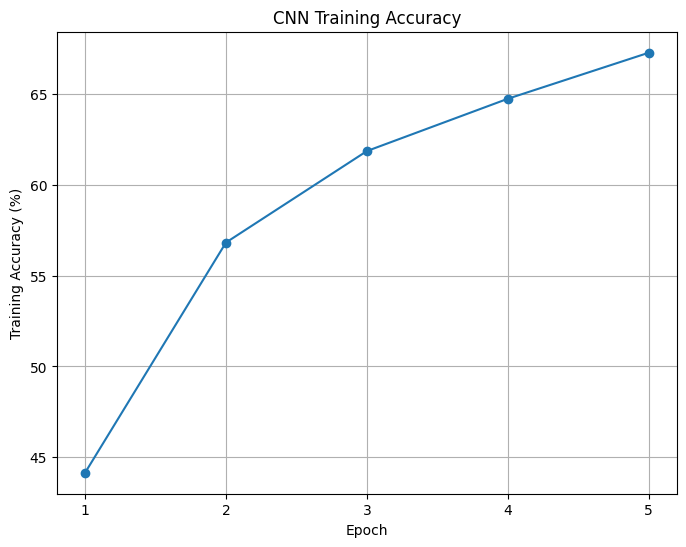

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(
    epochs,
    [acc * 100 for acc in cnn_train_accuracies],
    marker='o'
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("CNN Training Accuracy")

plt.xticks(list(epochs))
plt.grid(True)

plt.show()

#Improved CNN Model:
Includes Batch Normalization, Dropout and Scheduler with 10 epochs.

In [ ]:
class ImprovedCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(128, 10)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x

improved_cnn = ImprovedCNN()

print(improved_cnn)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in improved_cnn.parameters()
        if p.requires_grad
    )
)

ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 545290


In [ ]:
from torch.optim import lr_scheduler

improved_criterion = nn.CrossEntropyLoss()

improved_optimizer = Adam(
    improved_cnn.parameters(),
    lr=0.001
)

scheduler = lr_scheduler.StepLR(
    improved_optimizer,
    step_size=5,
    gamma=0.1
)

In [ ]:
num_epochs = 10

improved_train_losses = []
improved_train_accuracies = []

for epoch in range(num_epochs):

    improved_cnn.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        outputs = improved_cnn(images)

        loss = improved_criterion(outputs, labels)

        improved_optimizer.zero_grad()

        loss.backward()

        improved_optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    improved_train_losses.append(epoch_loss)
    improved_train_accuracies.append(epoch_accuracy)

    scheduler.step()

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.4f} "
        f"LR: {scheduler.get_last_lr()[0]:.6f}"
    )

Epoch [1/10] Loss: 1.8298 Accuracy: 0.3003 LR: 0.001000
Epoch [2/10] Loss: 1.6620 Accuracy: 0.3644 LR: 0.001000
Epoch [3/10] Loss: 1.5894 Accuracy: 0.3937 LR: 0.001000
Epoch [4/10] Loss: 1.5460 Accuracy: 0.4092 LR: 0.001000
Epoch [5/10] Loss: 1.5158 Accuracy: 0.4237 LR: 0.000100
Epoch [6/10] Loss: 1.4507 Accuracy: 0.4503 LR: 0.000100
Epoch [7/10] Loss: 1.4293 Accuracy: 0.4561 LR: 0.000100
Epoch [8/10] Loss: 1.4308 Accuracy: 0.4560 LR: 0.000100
Epoch [9/10] Loss: 1.4176 Accuracy: 0.4613 LR: 0.000100
Epoch [10/10] Loss: 1.4157 Accuracy: 0.4605 LR: 0.000010


#Improved CNN Evaluation:

In [ ]:
improved_cnn.eval()

improved_test_loss = 0.0
improved_correct = 0
improved_total = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = improved_cnn(images)

        loss = improved_criterion(outputs, labels)

        improved_test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        improved_correct += (predictions == labels).sum().item()
        improved_total += labels.size(0)

improved_test_loss /= improved_total
improved_test_accuracy = improved_correct / improved_total

print(f"Improved CNN Test Loss: {improved_test_loss:.4f}")
print(f"Improved CNN Test Accuracy: {improved_test_accuracy:.4f}")

Improved CNN Test Loss: 1.0850
Improved CNN Test Accuracy: 0.6256


#Strong CNN Model:
3 level convolution.

In [ ]:
class StrongCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(2, 2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(2, 2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x

strong_cnn = StrongCNN()

print(strong_cnn)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in strong_cnn.parameters()
        if p.requires_grad
    )
)

StrongCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1,

In [ ]:
strong_criterion = nn.CrossEntropyLoss()

strong_optimizer = Adam(
    strong_cnn.parameters(),
    lr=0.001
)

In [ ]:
num_epochs = 10

strong_train_losses = []
strong_train_accuracies = []

for epoch in range(num_epochs):

    strong_cnn.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        outputs = strong_cnn(images)

        loss = strong_criterion(outputs, labels)

        strong_optimizer.zero_grad()

        loss.backward()

        strong_optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    strong_train_losses.append(epoch_loss)
    strong_train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.4f} "
    )

Epoch [1/10] Loss: 1.3342 Accuracy: 0.5082 
Epoch [2/10] Loss: 0.8925 Accuracy: 0.6817 
Epoch [3/10] Loss: 0.7600 Accuracy: 0.7316 
Epoch [4/10] Loss: 0.6764 Accuracy: 0.7633 
Epoch [5/10] Loss: 0.6257 Accuracy: 0.7815 
Epoch [6/10] Loss: 0.5783 Accuracy: 0.7990 
Epoch [7/10] Loss: 0.5471 Accuracy: 0.8118 
Epoch [8/10] Loss: 0.5209 Accuracy: 0.8202 
Epoch [9/10] Loss: 0.4913 Accuracy: 0.8297 
Epoch [10/10] Loss: 0.4717 Accuracy: 0.8356 


#Strong CNN Evaluation:

In [ ]:
strong_cnn.eval()

strong_test_loss = 0.0
strong_correct = 0
strong_total = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = strong_cnn(images)

        loss = strong_criterion(outputs, labels)

        strong_test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        strong_correct += (predictions == labels).sum().item()
        strong_total += labels.size(0)

strong_test_loss /= strong_total
strong_test_accuracy = strong_correct / strong_total

print(f"Strong CNN Test Loss: {strong_test_loss:.4f}")
print(f"Strong CNN Test Accuracy: {strong_test_accuracy:.4f}")

Strong CNN Test Loss: 0.4992
Strong CNN Test Accuracy: 0.8322


#Conclusion:
The project successfully demonstrated an end-to-end computer vision classification pipeline using PyTorch and CNNs.

The experiments showed a clear progression in performance:

Baseline NN → 40.20%

Original CNN → 69.33%

Strong CNN → 83.22%

The final Strong CNN improved test accuracy by 43.02 percentage points compared with the baseline neural network and by 13.89 percentage points compared with the original CNN.

The results demonstrate the importance of using convolutional architectures for image data because CNNs can learn local spatial patterns such as edges, textures, shapes, and increasingly complex visual features.

The final model's 83.22% test accuracy and very small 0.34 percentage-point train/test gap indicate that the model learned useful representations without exhibiting substantial overfitting.

The project also demonstrated an important practical ML lesson: model improvements must be validated experimentally. The BatchNorm/Dropout/Scheduler experiment performed worse than the original CNN, while the deeper Strong CNN produced a substantial improvement.

Overall, this project establishes practical experience with PyTorch, CNN architecture design, image preprocessing, data augmentation, model training, evaluation, and error analysis.

Key Learning Outcomes
* Working with image datasets using PyTorch
* Building custom CNN architectures
* Understanding convolution, pooling, and feature extraction
* Applying image augmentation
* Normalizing image data
* Using Cross-Entropy Loss for multiclass classification
* Training models with Adam
* Comparing neural-network architectures experimentally
* Evaluating models using loss and accuracy
* Analyzing confusion matrices and classification reports
* Identifying class-specific difficulties
* Recognizing underfitting and overfitting
* Understanding why deeper CNN architectures can improve feature learning

Final model: Strong CNN

Final test accuracy: 83.22%

Final test loss: 0.4992

#Steps Performed:

##Dataset Exploration

The dataset was inspected to understand:

* Number of training and testing samples
* Image dimensions
* Number of channels
* Pixel value range
* Class distribution
* Class labels and mappings
* Representative images from each class

The images were confirmed to be 32×32 RGB images with pixel values ranging from 0 to 255.

##Data Preprocessing

The images were converted into PyTorch tensors and normalized using CIFAR-10 channel statistics.

For the training set, data augmentation was applied using:

* Random horizontal flipping
* Random cropping with padding

The test set was normalized without random augmentation.

This helps the model generalize better while keeping evaluation consistent.

##DataLoader Preparation

PyTorch DataLoaders were created with:

* Batch size: 64
* Training data shuffled
* Test data not shuffled

The resulting input tensor shape was: [64, 3, 32, 32]

##Baseline Neural Network

A fully connected neural network was implemented as a baseline.

Architecture:

* Input: 3 × 32 × 32
* Flatten
* Linear: 3072 → 128
* ReLU
* Linear: 128 → 10

Result: 40.20% test accuracy

This established a baseline for evaluating whether convolutional architectures provide a meaningful improvement.

##Original CNN

A convolutional model was then implemented using two convolutional blocks.

* Input
* Conv2D 3 → 32
* ReLU
* MaxPool
* Conv2D 32 → 64
* ReLU
* MaxPool
* Fully Connected
* 10 Classes

Result: 69.33% test accuracy

This demonstrated a substantial improvement over the baseline neural network.

##CNN Experiment with BatchNorm, Dropout and Scheduler

A second experiment introduced:

* Batch Normalization
* Dropout
* Learning-rate scheduling

The model achieved: 62.56% test accuracy

Rather than improving performance, this configuration underfit the training data. This experiment demonstrated that architectural and optimization changes need to be validated empirically rather than assumed to improve performance.

##Strong CNN

A deeper CNN was then implemented with three convolutional blocks.

The architecture progressively increased feature channels: 3 → 32 → 64 → 128

while reducing spatial dimensions: 32×32 → 16×16 → 8×8 → 4×4

The final classifier operated on: 128 × 4 × 4 = 2048 features

The model was trained for 10 epochs using:

* Cross-Entropy Loss
* Adam optimizer
* Learning rate: 0.001

##Final Evaluation

The Strong CNN achieved:

* Training accuracy: 83.56%
* Test accuracy: 83.22%
* Test loss: 0.4992

The train-test accuracy gap was only: 0.34 percentage points

This indicates that the final model generalized well to the test set, with no substantial train/test performance gap.